In [2]:
"""
red_NN.py - Reto 9 (Data mining)  
 
Red neuronal que predice el payoff de la opcion asiatica geometrica de BBVA.
Entrada: ../DATOS/TRANSFORMADOS/datos_sinteticos.npy -> (100000, 21, 3), precios con S0 = 100
 
Que hace (cada parte se activa/desactiva en AJUSTES):
  1. COMPARACION de arquitecturas: MLP (linea base), RNN, GRU, LSTM, LSTM apilada, GRU bidireccional.
     Rendimiento (RMSE, MAE, R2, error de prima) y eficiencia (parametros, tiempos).
  2. VALIDACION CRUZADA k-fold de los modelos candidatos (media +- desviacion).
  3. TABLA de la prima en distintos instantes t (Monte Carlo y red).
Guarda tablas (.csv) y graficos (.png) en resultados/.
"""
import os
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn import metrics
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
 

In [2]:
%pip install torch scikit-learn scipy

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 6.7 MB/s eta 0:00:19
   - -------------------------------------- 3.4/124.1 MB 11.3 MB/s eta 0:00:11
   - -------------------------------------- 6.0/124.1 MB 12.3 MB/s eta 0:00:10
   -- ------------------------------------- 7.1/124.1 MB 10.5 MB/s eta 0:00:12
   -- ------------------------------------- 8.4/124.1 MB 8.9 MB/s eta 0:00:13
   --- ------------------------------------ 10.7/124.1 MB 9.6 MB/s eta 0:00:12
   ---- ----------------------------------- 14.2/124.1 MB 10.6 MB/s eta 0:00:11
   ----- ---------------------------------- 18.1/124.1 MB 11.7 MB/s eta 0:00:10
   ------ --------------------------------- 21.5/124.1 MB 12.3 MB/s eta 0:00:09
   ------- -------------------------------- 23.6/124.1 MB 12.2 MB/s eta 0:00:09
   -------- ------------------------------- 25.4/124.1 MB 11.8 MB/s eta 0:00:09
   --------- ------------------------------ 28.8/124.1 MB

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Número de pasos temporales detectados: 19
Modo: rapido | simulaciones: 20000 | % payoffs = 0: 24.9% | pasos iniciales fijos: 4

Prima Monte Carlo (20000 sims): 0.1631 +- 0.0012
Tiempo Monte Carlo (3000 trayectorias): 0.0101 s

[COMPARACION] MLP
    [MLP] epoca 10: train loss 0.016362 | valid loss 0.005584
    [MLP] epoca 20: train loss 0.011468 | valid loss 0.003203
    [MLP] epoca 30: train loss 0.009081 | valid loss 0.001925
    [MLP] epoca 40: train loss 0.007272 | valid loss 0.001392
    [MLP] epoca 50: train loss 0.006852 | valid loss 0.000935
    [MLP] epoca 60: train loss 0.006227 | valid loss 0.000745
[COMPARACION] RNN
    [RNN] epoca 10: train loss 0.053816 | valid loss 0.042691
    [RNN] epoca 20: train loss 0.036935 | valid loss 0.027407
    [RNN] epoca 30: train loss 0.031636 | valid loss 0.029559
    [RNN] epoca 40: train loss 0.025921 | valid loss 0.018499
    [RNN] epoca 50: train loss 0.019115 | valid loss 0.011529
    [RNN] epoca 60: train loss 0.015778 | valid loss 0.

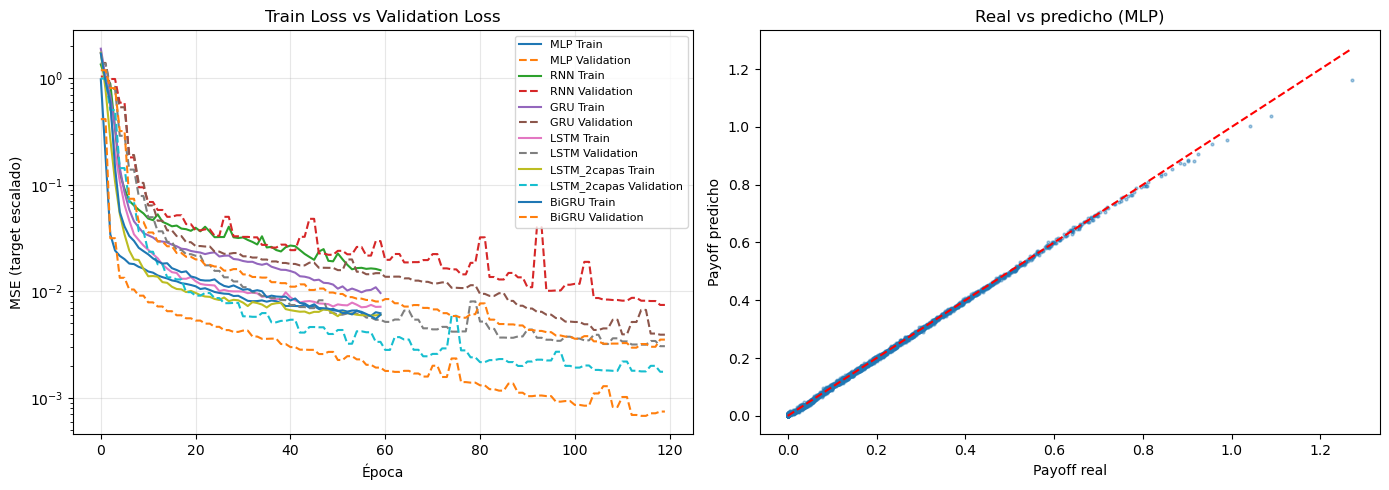

    [MLP fold 1] epoca 10: train loss 0.016429 | valid loss 0.004982
    [MLP fold 1] epoca 20: train loss 0.011834 | valid loss 0.002570
    [MLP fold 1] epoca 30: train loss 0.009036 | valid loss 0.001469
    [MLP fold 1] epoca 40: train loss 0.007436 | valid loss 0.001011
    [MLP fold 1] epoca 50: train loss 0.006963 | valid loss 0.000870
    [MLP fold 1] epoca 60: train loss 0.005968 | valid loss 0.000498
[CV MLP] fold 1/5: RMSE 0.0040 | R2 0.9995 | err prima +0.30% | 60 epocas | 6s
    [MLP fold 2] epoca 10: train loss 0.015743 | valid loss 0.004132
    [MLP fold 2] epoca 20: train loss 0.011567 | valid loss 0.001948
    [MLP fold 2] epoca 30: train loss 0.008928 | valid loss 0.001648
    [MLP fold 2] epoca 40: train loss 0.007870 | valid loss 0.000834
    [MLP fold 2] epoca 50: train loss 0.007486 | valid loss 0.000625
    [MLP fold 2] epoca 60: train loss 0.006877 | valid loss 0.000620
[CV MLP] fold 2/5: RMSE 0.0044 | R2 0.9994 | err prima -1.03% | 60 epocas | 6s
    [MLP fold 

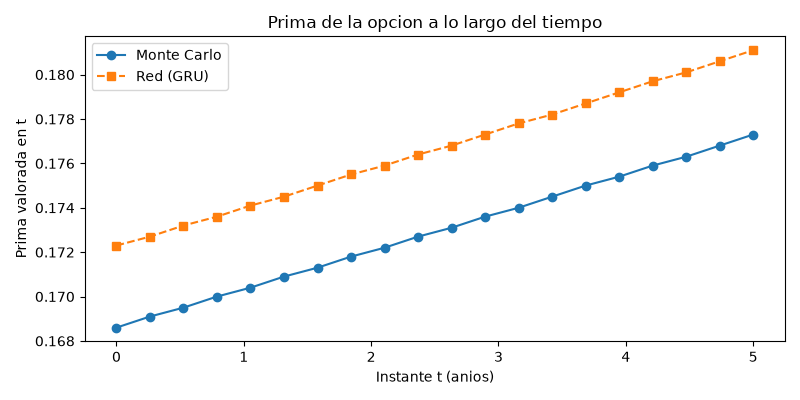

In [4]:


MODO = 'rapido'             # 'rapido' (pruebas) o 'completo' (resultados finales, MUCHO mas lento)
RUN_COMPARACION = True
RUN_CV = True
RUN_TABLA = True
 
DATA_PATH = os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'datos_sinteticos.npy')
OUT_DIR = 'resultados'
 
if MODO == 'rapido':
    N_SIMS, EPOCHS, PATIENCE, BATCH_SIZE = 20000, 60, 8, 512
else:
    N_SIMS, EPOCHS, PATIENCE, BATCH_SIZE = 100000, 150, 10, 256
 
LR = 0.001
UNITS = 32
DROPOUT = 0.05
SEED = 0
K = 5                                    # folds de la validacion cruzada
CV_MODELOS = ['MLP', 'GRU', 'LSTM']      # nombres de CONFIGS a validar
MODELO_FINAL = 'GRU'                     # modelo para la tabla por instantes
 
MU, TTM, N_PASOS = 0.01, 5, 20           # tasa libre de riesgo, vencimiento , pasos
DT = TTM / N_PASOS
 
CONFIGS = {
    'MLP':         dict(tipo='mlp',  units=64, capas=2),                  # linea base sin memoria
    'RNN':         dict(tipo='rnn',  units=UNITS, capas=1),
    'GRU':         dict(tipo='gru',  units=UNITS, capas=1),
    'LSTM':        dict(tipo='lstm', units=UNITS, capas=1),
    'LSTM_2capas': dict(tipo='lstm', units=UNITS, capas=2),               # apilada
    'BiGRU':       dict(tipo='gru',  units=UNITS, capas=1, bi=True),      # bidireccional
}
 
 
# A. PAYOFF Y PRIMA

def payoff_bbva(X_ratio):
    """X_ratio: (N, n, m) con S_ti / S_0."""
    return np.maximum(np.exp(np.log(X_ratio).mean(axis=(1, 2))) - 1.0, 0.0)
 
 
def prima(V_T):
    """Prima en t0: payoff descontado."""
    return np.exp(-MU * TTM) * V_T
 
 
def estimar_parametros(data):
    """Estima sigma, rho y d (pasos iniciales iguales en todas las simulaciones) desde los precios."""
    r = np.diff(np.log(data), axis=1)
    varia = r.std(axis=0).max(axis=1) > 1e-9
    d = int(np.argmax(varia)) if varia.any() else r.shape[1]
    r_al = r[:, d:, :].reshape(-1, r.shape[2])
    sigma = r_al.std(axis=0, ddof=1) / np.sqrt(DT)
    rho = np.corrcoef(r_al, rowvar=False)
    return sigma, rho, d
 
 
# ======================= B. MODELOS =======================
class RNN(torch.nn.Module):
    def __init__(self, tipo, units, capas=1, bi=False, dropout=DROPOUT):
        super().__init__()
        Cell = {'rnn': torch.nn.RNN, 'lstm': torch.nn.LSTM, 'gru': torch.nn.GRU}[tipo]
        self.rnn = Cell(3, units, num_layers=capas, batch_first=True, bidirectional=bi,
                        dropout=dropout if capas > 1 else 0.0)
        self.bi = bi
        self.dropout = torch.nn.Dropout(dropout)
        self.out = torch.nn.Linear(units * (2 if bi else 1), 1)
 
    def forward(self, x):
        _, h = self.rnn(x)
        if isinstance(h, tuple):                                  # LSTM devuelve (h, c)
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]   # estado final de la ultima capa
        return self.out(self.dropout(h)).squeeze(-1)              
 
 
class MLP(torch.nn.Module):
    """Linea base: recibe los log-retornos aplanados, sin memoria."""
    def __init__(self, units, capas, input_dim, dropout=DROPOUT):
        super().__init__()
        l = [
            torch.nn.Flatten(),
            torch.nn.Linear(input_dim, units),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout)
        ]

        for _ in range(capas - 1):
            l += [
                torch.nn.Linear(units, units),
                torch.nn.ReLU(),
                torch.nn.Dropout(dropout)
            ]

        l.append(torch.nn.Linear(units, 1))
        self.net = torch.nn.Sequential(*l)

    def forward(self, x):
        return self.net(x).squeeze(-1)
def crear_modelo(cfg, input_dim):
    if cfg['tipo'] == 'mlp':
        return MLP(cfg['units'], cfg['capas'], input_dim)

    return RNN(cfg['tipo'], cfg['units'], cfg['capas'], cfg.get('bi', False))
 
 
#  C. ENTRENAMIENTO Y EVALUACION 
def preparar(X, y, idx_tr, idx_val, idx_te):
    """Escalado ajustado SOLO con el train. Devuelve tensores y la escala del target."""
    m, s = X[idx_tr].mean((0, 1)), X[idx_tr].std((0, 1))
    ys = y[idx_tr].std()
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    f = lambda idx: (t((X[idx] - m) / s), t(y[idx] / ys))
    return f(idx_tr), f(idx_val), f(idx_te), ys
 
 
def entrenar(cfg, X_tr, y_tr, X_val, y_val, seed, etiqueta=''):
    """MSE + Adam + scheduler (ReduceLROnPlateau) + early stopping. Devuelve modelo, historia, tiempo, epocas."""
    torch.manual_seed(seed)
    model = crear_modelo(cfg, X_tr.shape[1] * X_tr.shape[2])
    criterion = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    dl = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    best, best_state, count = float('inf'), None, 0
    hist = {
    'train': [],
    'val': []
}
    t0 = time.perf_counter()
 
    for epoch in range(EPOCHS):
        model.train()

        train_loss = 0.0
        n_train = 0

        for xb, yb in dl:
            optimizer.zero_grad()

            loss = criterion(model(xb), yb)
            loss.backward()

            optimizer.step()

            train_loss += loss.item() * len(xb)
            n_train += len(xb)

        train_loss /= n_train

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val), y_val).item()

    # Guardar pérdidas
        hist['train'].append(train_loss)
        hist['val'].append(val_loss)

        scheduler.step(val_loss)
        hist['val'].append(val_loss)
        if (epoch + 1) % 10 == 0:
            print(
                f'    [{etiqueta}] epoca {epoch + 1}: '
                f'train loss {train_loss:.6f} | '
                f'valid loss {val_loss:.6f}'
            )
            if val_loss <= best:
                best, count = val_loss, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                count += 1
                if count >= PATIENCE:
                    break
    
    t_train = time.perf_counter() - t0
    model.load_state_dict(best_state)                  
    model.eval()
    return model, hist, t_train, epoch + 1
 
 
def evaluar(model, X_te, y_te, ys):
    tiempos = []                                       # tiempo de inferencia: mejor de 5 pasadas
    for _ in range(5):
        t0 = time.perf_counter()
        with torch.no_grad():
            pred = model(X_te).numpy() * ys
        tiempos.append(time.perf_counter() - t0)
    pred = np.maximum(pred, 0.0)                       # el payoff no puede ser negativo
    real = y_te.numpy() * ys
    err = pred - real
    pos = real > 0
    p_real, p_pred = prima(real).mean(), prima(pred).mean()
    return dict(RMSE=np.sqrt(metrics.mean_squared_error(real, pred)),
                MAE=metrics.mean_absolute_error(real, pred),
                R2=metrics.r2_score(real, pred),
                RMSE_pos=np.sqrt(np.mean(err[pos] ** 2)),     # error solo donde hay payoff
                sesgo_cero=pred[~pos].mean(),                 # lo que predice donde el payoff real es 0
                prima_real=p_real, prima_pred=p_pred,
                err_prima=100 * (p_pred - p_real) / p_real,
                t_infer=min(tiempos), real=real, pred=pred)
 
 
def tiempo_montecarlo(n, sigma, rho):
    """Referencia de eficiencia: simular n trayectorias correladas (numpy) y calcular su payoff."""
    rng = np.random.default_rng(0)
    t0 = time.perf_counter()
    L = np.linalg.cholesky(rho)
    z = rng.standard_normal((n, N_PASOS, 3))
    inc = (MU - sigma ** 2 / 2) * DT + sigma * np.sqrt(DT) * (z @ L.T)
    payoff_bbva(np.exp(np.cumsum(inc, axis=1)))
    return time.perf_counter() - t0
 
 
def tabla_instantes(real_pay, pred_pay, X_ratio_te, sigma, rho, d):
    """Prima en cada instante t_v = v*dt, valorada en t_v:
       Monte Carlo = payoff real descontado de T a t_v | Red = payoff predicho descontado."""
    filas = []
    for v in range(N_PASOS + 1):
        desc = np.exp(-MU * (N_PASOS - v) * DT)
        p_mc, p_red = desc * real_pay.mean(), desc * pred_pay.mean()
        filas.append(dict(paso=v, t_anios=v * DT, prima_MC=p_mc, prima_red=p_red,
                          err_red_pct=100 * (p_red - p_mc) / p_mc))
    return pd.DataFrame(filas)
 
 
#  D. MAIN 
if __name__ == '__main__':
    os.makedirs(OUT_DIR, exist_ok=True)
    np.random.seed(SEED)
 
    # ---- Datos ----
    data = np.load(DATA_PATH)

    # Ajustar automáticamente el número de pasos temporales
    N_PASOS = data.shape[1] - 1
    DT = TTM / N_PASOS

    print(f'Número de pasos temporales detectados: {N_PASOS}')

    data = data[np.random.permutation(len(data))[:N_SIMS]]

    X_ratio = data[:, 1:, :] / data[:, :1, :]                   
    y = payoff_bbva(X_ratio)                                      
    X = np.diff(np.log(X_ratio), axis=1, prepend=0.0)             
    sigma, rho, d = estimar_parametros(data)
    print(f'Modo: {MODO} | simulaciones: {len(X)} | % payoffs = 0: {100 * np.mean(y == 0):.1f}% '
          f'| pasos iniciales fijos: {d}')
 
    # split 70 / 15 / 15 
    n_tr, n_val = int(.70 * len(X)), int(.15 * len(X))
    idx = np.arange(len(X))
    idx_tr, idx_val, idx_te = idx[:n_tr], idx[n_tr:n_tr + n_val], idx[n_tr + n_val:]
    (Xtr, ytr), (Xva, yva), (Xte, yte), ys = preparar(X, y, idx_tr, idx_val, idx_te)
 
    resultados, historias = {}, {}
 
    #  1. Comparacion de arquitecturas
    if RUN_COMPARACION:
        p_mc = prima(y)
        t_mc = tiempo_montecarlo(len(Xte), sigma, rho)
        print(f'\nPrima Monte Carlo ({len(y)} sims): {p_mc.mean():.4f} +- {p_mc.std() / np.sqrt(len(y)):.4f}')
        print(f'Tiempo Monte Carlo ({len(Xte)} trayectorias): {t_mc:.4f} s\n')
 
        for nombre, cfg in CONFIGS.items():
            print(f'[COMPARACION] {nombre}')
            model, historias[nombre], t_train, epocas = entrenar(cfg, Xtr, ytr, Xva, yva, SEED, nombre)
            r = evaluar(model, Xte, yte, ys)
            r.update(params=sum(p.numel() for p in model.parameters()), t_train=t_train, epocas=epocas)
            resultados[nombre] = r
 
        print(f"\n{'Modelo':<12} {'Params':>7} {'Epocas':>6} {'T.entr(s)':>9} {'T.infer(s)':>10} {'RMSE':>8} "
              f"{'MAE':>8} {'R2':>7} {'RMSE>0':>8} {'Prima real':>11} {'Prima pred':>11} {'Err prima':>10}")
        for nombre, r in resultados.items():
            print(f"{nombre:<12} {r['params']:>7} {r['epocas']:>6} {r['t_train']:>9.1f} {r['t_infer']:>10.4f} "
                  f"{r['RMSE']:>8.4f} {r['MAE']:>8.4f} {r['R2']:>7.3f} {r['RMSE_pos']:>8.4f} "
                  f"{r['prima_real']:>11.4f} {r['prima_pred']:>11.4f} {r['err_prima']:>9.2f}%")
        print(f'\nTiempo Monte Carlo (mismas trayectorias): {t_mc:.4f} s')
 
        pd.DataFrame([{k: v for k, v in dict(modelo=n, **r).items() if k not in ('real', 'pred')}
                      for n, r in resultados.items()]).to_csv(
            os.path.join(OUT_DIR, 'tabla_arquitecturas.csv'), index=False)
 
        fig, axs = plt.subplots(1, 2, figsize=(14, 5))
        for nombre, h in historias.items():

            axs[0].plot(
                h['train'],
                linestyle='-',
                label=f'{nombre} Train'
            )

            axs[0].plot(
                h['val'],
                linestyle='--',
                label=f'{nombre} Validation'
            )

        axs[0].set_yscale('log')
        axs[0].set_xlabel('Época')
        axs[0].set_ylabel('MSE (target escalado)')
        axs[0].set_title('Train Loss vs Validation Loss')
        axs[0].legend(fontsize=8)
        axs[0].grid(alpha=0.3)
        mejor = min(resultados, key=lambda c: resultados[c]['RMSE'])
        r = resultados[mejor]
        axs[1].scatter(r['real'], r['pred'], s=4, alpha=.4)
        lim = [0, max(r['real'].max(), r['pred'].max())]
        axs[1].plot(lim, lim, 'r--')
        axs[1].set_xlabel('Payoff real')
        axs[1].set_ylabel('Payoff predicho')
        axs[1].set_title(f'Real vs predicho ({mejor})')
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, 'comparacion_arquitecturas.png'), dpi=150)
        plt.show()
 
    # 2. Validacion cruzada 
    if RUN_CV:
        filas = []
        kf = KFold(K, shuffle=True, random_state=SEED)
        for nombre in CV_MODELOS:
            for fold, (i_trval, i_te) in enumerate(kf.split(X)):
                nv = int(0.15 * len(i_trval))
                i_val, i_tr = i_trval[:nv], i_trval[nv:]
                (a, b), (c, e), (f_, g), ys_f = preparar(X, y, i_tr, i_val, i_te)
                model, _, t_train, epocas = entrenar(CONFIGS[nombre], a, b, c, e, SEED + fold,
                                                     f'{nombre} fold {fold + 1}')
                r = evaluar(model, f_, g, ys_f)
                filas.append(dict(modelo=nombre, fold=fold + 1, epocas=epocas, t_entreno_s=t_train,
                                  t_infer_s=r['t_infer'], RMSE=r['RMSE'], MAE=r['MAE'], R2=r['R2'],
                                  err_prima_pct=r['err_prima']))
                print(f'[CV {nombre}] fold {fold + 1}/{K}: RMSE {r["RMSE"]:.4f} | R2 {r["R2"]:.4f} | '
                      f'err prima {r["err_prima"]:+.2f}% | {epocas} epocas | {t_train:.0f}s')
        cv = pd.DataFrame(filas)
        cv.to_csv(os.path.join(OUT_DIR, 'cv_detalle.csv'), index=False)
        cols = ['RMSE', 'MAE', 'R2', 'err_prima_pct', 't_entreno_s', 't_infer_s']
        g_ = cv.groupby('modelo', sort=False)[cols]
        resumen = g_.mean().join(g_.std(), lsuffix='_media', rsuffix='_std')
        resumen.to_csv(os.path.join(OUT_DIR, 'cv_resumen.csv'))
        print(f'\n=== VALIDACION CRUZADA ({K} folds): media y desviacion entre folds ===')
        print(resumen.round(5).T.to_string())
        print('\nSi la diferencia entre dos modelos es menor que su desviacion entre folds, '
              'no se puede afirmar que uno sea mejor.')
 
    # ---------- 3. Tabla de la prima por instantes ----------
    if RUN_TABLA:
        if MODELO_FINAL in resultados:                                # reutiliza el modelo ya entrenado
            r = resultados[MODELO_FINAL]
        else:
            model, _, _, _ = entrenar(CONFIGS[MODELO_FINAL], Xtr, ytr, Xva, yva, SEED, MODELO_FINAL)
            r = evaluar(model, Xte, yte, ys)
        tabla = tabla_instantes(r['real'], r['pred'], X_ratio[idx_te], sigma, rho, d)
        tabla.to_csv(os.path.join(OUT_DIR, 'tabla_prima_instantes.csv'), index=False)
        print(f'\n=== PRIMA EN DISTINTOS INSTANTES ({MODELO_FINAL}, media sobre las trayectorias de test) ===')
        print(tabla.round(4).to_string(index=False))
 
        plt.figure(figsize=(8, 4))
        plt.plot(tabla['t_anios'], tabla['prima_MC'], 'o-', label='Monte Carlo')
        plt.plot(tabla['t_anios'], tabla['prima_red'], 's--', label=f'Red ({MODELO_FINAL})')
        plt.xlabel('Instante t (anios)')
        plt.ylabel('Prima valorada en t')
        plt.title('Prima de la opcion a lo largo del tiempo')
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, 'prima_instantes.png'), dpi=150)
        plt.show()

Modo: rapido | datos: (20000, 20, 3) -> 19 pasos, dt = 0.2632 anos | simulaciones usadas: 20000
% payoffs = 0: 24.9% | pasos iniciales fijos: 4 | sigma estimada: [0.195 0.195 0.292]

Prima Monte Carlo (20000 sims): 0.1631 +- 0.0012
Tiempo Monte Carlo (3000 trayectorias, numpy): 0.0052 s

[COMPARACION] MLP
    [MLP] epoca 10: train 0.016362 | valid 0.005584
    [MLP] epoca 20: train 0.011468 | valid 0.003203
    [MLP] epoca 30: train 0.009081 | valid 0.001925
    [MLP] epoca 40: train 0.007272 | valid 0.001392
    [MLP] epoca 50: train 0.006852 | valid 0.000935
    [MLP] epoca 60: train 0.006227 | valid 0.000745

[COMPARACION] RNN
    [RNN] epoca 10: train 0.053816 | valid 0.042691
    [RNN] epoca 20: train 0.036935 | valid 0.027407
    [RNN] epoca 30: train 0.031636 | valid 0.029559
    [RNN] epoca 40: train 0.025921 | valid 0.018499
    [RNN] epoca 50: train 0.019115 | valid 0.011529
    [RNN] epoca 60: train 0.015778 | valid 0.007451

[COMPARACION] GRU
    [GRU] epoca 10: train 0.035

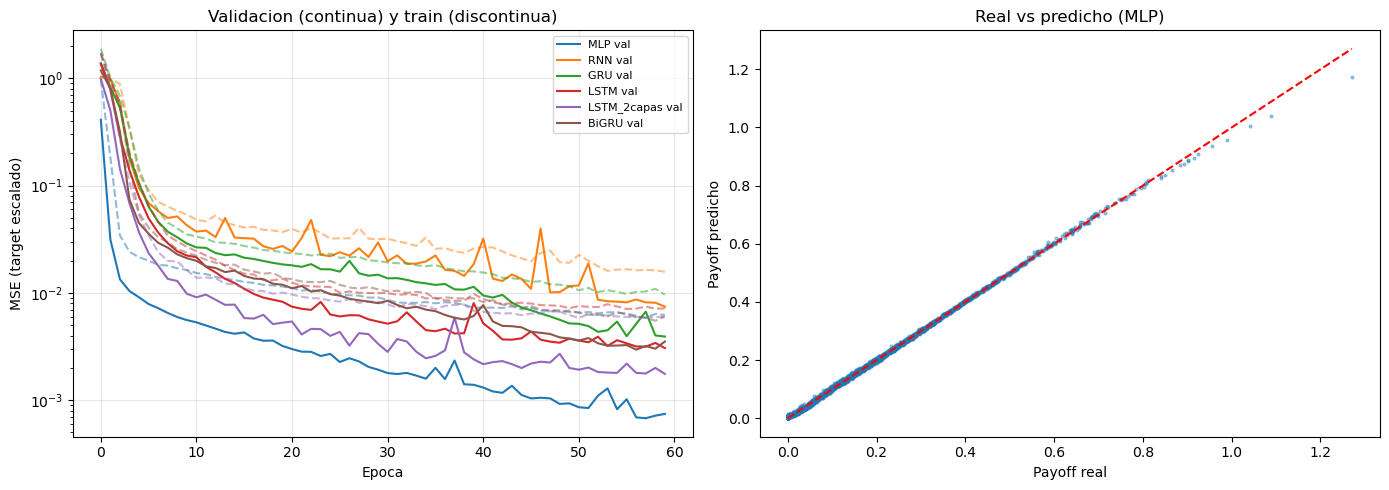


Mejor red recurrente: LSTM_2capas | modelo final para la tabla: LSTM_2capas

[HIPERPARAMETRO] LSTM_2capas: units = 16
    [units=16] epoca 10: train 0.054494 | valid 0.034877
    [units=16] epoca 20: train 0.027833 | valid 0.014578
    [units=16] epoca 30: train 0.021835 | valid 0.010318
    [units=16] epoca 40: train 0.018282 | valid 0.007487
    [units=16] epoca 50: train 0.015816 | valid 0.007155
    [units=16] epoca 60: train 0.014875 | valid 0.005656

[HIPERPARAMETRO] LSTM_2capas: units = 32  (base, ya entrenado)

[HIPERPARAMETRO] LSTM_2capas: units = 64
    [units=64] epoca 10: train 0.008194 | valid 0.005468
    [units=64] epoca 20: train 0.005291 | valid 0.001982
    [units=64] epoca 30: train 0.003780 | valid 0.001489
    [units=64] epoca 40: train 0.003292 | valid 0.001185
    [units=64] epoca 50: train 0.003095 | valid 0.001169
    [units=64] epoca 60: train 0.002930 | valid 0.001022

[HIPERPARAMETRO] LSTM_2capas: lr = 0.001  (base, ya entrenado)

[HIPERPARAMETRO] LSTM_2cap

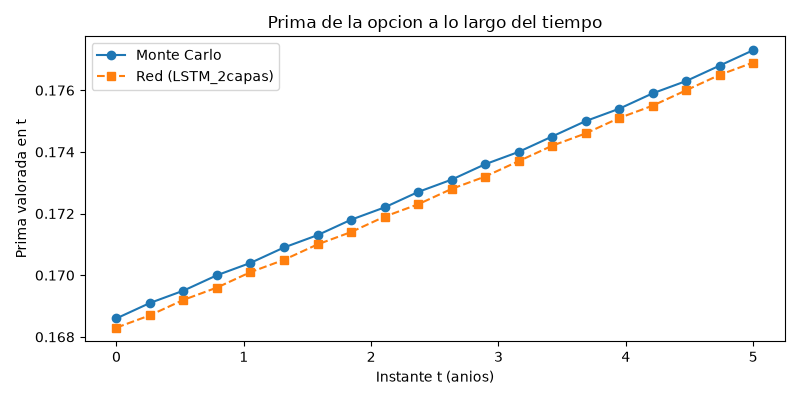


Listo. Tablas y graficos guardados en la carpeta "resultados/".


In [ ]:
MODO = 'rapido'            # 'rapido' = pruebas (minutos)  |  'completo' = resultados finales (MUCHO mas lento)
RUN_COMPARACION = True
RUN_HIPERPARAMS = True
RUN_SEMILLAS = True
RUN_CV = True
RUN_TABLA = True


DATA_PATH = os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'datos_sinteticos.npy')
OUT_DIR = 'resultados'

if MODO == 'rapido':
    N_SIMS, EPOCHS, PATIENCE, BATCH_SIZE = 20000, 60, 8, 512
else:
    N_SIMS, EPOCHS, PATIENCE, BATCH_SIZE = 100000, 150, 10, 256

LR = 0.001
UNITS = 32
DROPOUT = 0.05
SEED = 0
SEEDS = [0, 1, 2]                         # semillas para el bloque 3
K = 5                                     # folds de la validacion cruzada
CV_MODELOS = ['MLP', 'GRU', 'LSTM']       # nombres de CONFIGS a validar
MODELO_FINAL = 'auto'                     # 'auto' = mejor red recurrente de la comparacion (o un nombre de CONFIGS)
BARRIDO = {'units': [16, 32, 64], 'lr': [0.001, 0.003, 0.01], 'dropout': [0.0, 0.05, 0.2]}

MU, TTM, N_PASOS = 0.01, 5, 20            # tasa libre de riesgo, vencimiento (anos), pasos (se ajusta a los datos)
DT = TTM / N_PASOS

CONFIGS = {
    'MLP':         dict(tipo='mlp',  units=64, capas=2),                  # linea base sin memoria
    'RNN':         dict(tipo='rnn',  units=UNITS, capas=1),
    'GRU':         dict(tipo='gru',  units=UNITS, capas=1),
    'LSTM':        dict(tipo='lstm', units=UNITS, capas=1),
    'LSTM_2capas': dict(tipo='lstm', units=UNITS, capas=2),               # apilada
    'BiGRU':       dict(tipo='gru',  units=UNITS, capas=1, bi=True),      # bidireccional
}


#              A. PAYOFF Y PRIMA

def payoff_bbva(X_ratio):
    """X_ratio: (N, n, m) con S_ti / S_0."""
    return np.maximum(np.exp(np.log(X_ratio).mean(axis=(1, 2))) - 1.0, 0.0)


def prima(V_T):
    """Prima en t0: payoff descontado."""
    return np.exp(-MU * TTM) * V_T


def estimar_parametros(data):
    """Estima sigma, rho y d (pasos iniciales iguales en todas las simulaciones) desde los precios."""
    r = np.diff(np.log(data), axis=1)
    varia = r.std(axis=0).max(axis=1) > 1e-9
    d = int(np.argmax(varia)) if varia.any() else r.shape[1]
    r_al = r[:, d:, :].reshape(-1, r.shape[2])
    sigma = r_al.std(axis=0, ddof=1) / np.sqrt(DT)
    rho = np.corrcoef(r_al, rowvar=False)
    return sigma, rho, d


#                              B. MODELOS

class RNN(torch.nn.Module):
    def __init__(self, tipo, units, capas=1, bi=False, dropout=DROPOUT):
        super().__init__()
        Cell = {'rnn': torch.nn.RNN, 'lstm': torch.nn.LSTM, 'gru': torch.nn.GRU}[tipo]
        self.rnn = Cell(3, units, num_layers=capas, batch_first=True, bidirectional=bi,
                        dropout=dropout if capas > 1 else 0.0)
        self.bi = bi
        self.dropout = torch.nn.Dropout(dropout)
        self.out = torch.nn.Linear(units * (2 if bi else 1), 1)

    def forward(self, x):
        _, h = self.rnn(x)
        if isinstance(h, tuple):                                  # LSTM devuelve (h, c)
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]   # estado final de la ultima capa
        return self.out(self.dropout(h)).squeeze(-1)              # resumen de la trayectoria -> payoff


class MLP(torch.nn.Module):
    """Linea base: recibe los log-retornos aplanados, sin memoria."""
    def __init__(self, units, capas, input_dim, dropout=DROPOUT):
        super().__init__()
        capas_ = [torch.nn.Flatten(), torch.nn.Linear(input_dim, units), torch.nn.ReLU(), torch.nn.Dropout(dropout)]
        for _ in range(capas - 1):
            capas_ += [torch.nn.Linear(units, units), torch.nn.ReLU(), torch.nn.Dropout(dropout)]
        capas_.append(torch.nn.Linear(units, 1))
        self.net = torch.nn.Sequential(*capas_)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def crear_modelo(cfg, input_dim):
    dropout = cfg.get('dropout', DROPOUT)
    if cfg['tipo'] == 'mlp':
        return MLP(cfg['units'], cfg['capas'], input_dim, dropout)
    return RNN(cfg['tipo'], cfg['units'], cfg['capas'], cfg.get('bi', False), dropout)


#                   C. ENTRENAMIENTO Y EVALUACION
def preparar(X, y, idx_tr, idx_val, idx_te):
    """Escalado ajustado SOLO con el train. Devuelve ((Xtr,ytr),(Xva,yva),(Xte,yte), escala_target)."""
    m, s = X[idx_tr].mean((0, 1)), X[idx_tr].std((0, 1))
    ys = y[idx_tr].std()
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    f = lambda idx: (t((X[idx] - m) / s), t(y[idx] / ys))
    return f(idx_tr), f(idx_val), f(idx_te), ys


def entrenar(cfg, X_tr, y_tr, X_val, y_val, seed, etiqueta=''):
    """MSE + Adam + scheduler (ReduceLROnPlateau) + early stopping. Devuelve modelo, historia, tiempo, epocas."""
    torch.manual_seed(seed)
    model = crear_modelo(cfg, X_tr.shape[1] * X_tr.shape[2])
    criterion = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.get('lr', LR))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    dl = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    best, best_state, count = float('inf'), None, 0
    hist = {'train': [], 'val': []}
    t0 = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        train_loss, n_train = 0.0, 0
        for xb, yb in dl:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(xb)
            n_train += len(xb)
        train_loss /= n_train

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val), y_val).item()
        scheduler.step(val_loss)
        hist['train'].append(train_loss)
        hist['val'].append(val_loss)

        if (epoch + 1) % 10 == 0:
            print(f'    [{etiqueta}] epoca {epoch + 1}: train {train_loss:.6f} | valid {val_loss:.6f}')

        if val_loss <= best:
            best, count = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            count += 1
            if count >= PATIENCE:
                break

    t_train = time.perf_counter() - t0
    model.load_state_dict(best_state)                  # mejor modelo (en memoria)
    model.eval()
    return model, hist, t_train, epoch + 1


def evaluar(model, X_te, y_te, ys):
    tiempos = []                                       # tiempo de inferencia: mejor de 5 pasadas
    for _ in range(5):
        t0 = time.perf_counter()
        with torch.no_grad():
            pred = model(X_te).numpy() * ys
        tiempos.append(time.perf_counter() - t0)
    pred = np.maximum(pred, 0.0)                       # el payoff no puede ser negativo
    real = y_te.numpy() * ys
    err = pred - real
    pos = real > 0
    p_real, p_pred = prima(real).mean(), prima(pred).mean()
    return dict(RMSE=np.sqrt(metrics.mean_squared_error(real, pred)),
                MAE=metrics.mean_absolute_error(real, pred),
                R2=metrics.r2_score(real, pred),
                RMSE_pos=np.sqrt(np.mean(err[pos] ** 2)),     # error solo donde hay payoff
                sesgo_cero=pred[~pos].mean(),                 # lo que predice donde el payoff real es 0
                prima_real=p_real, prima_pred=p_pred,
                err_prima=100 * (p_pred - p_real) / p_real,
                t_infer=min(tiempos), real=real, pred=pred)


def correr(cfg, datos, seed, etiqueta):
    """Entrena una configuracion y la evalua en test."""
    (Xtr, ytr), (Xva, yva), (Xte, yte), ys = datos
    model, hist, t_train, epocas = entrenar(cfg, Xtr, ytr, Xva, yva, seed, etiqueta)
    r = evaluar(model, Xte, yte, ys)
    r.update(params=sum(p.numel() for p in model.parameters()), t_train=t_train, epocas=epocas, hist=hist)
    return r


def fila(nombre, r):
    return dict(modelo=nombre, params=r['params'], epocas=r['epocas'], t_entreno_s=round(r['t_train'], 1),
                t_infer_s=round(r['t_infer'], 4), RMSE=r['RMSE'], MAE=r['MAE'], R2=r['R2'],
                RMSE_pos=r['RMSE_pos'], sesgo_cero=r['sesgo_cero'], prima_pred=r['prima_pred'],
                err_prima_pct=r['err_prima'])


def tiempo_montecarlo(n, sigma, rho):
    """Referencia de eficiencia: simular n trayectorias correladas (numpy) y calcular su payoff."""
    rng = np.random.default_rng(0)
    t0 = time.perf_counter()
    L = np.linalg.cholesky(rho)
    z = rng.standard_normal((n, N_PASOS, 3))
    inc = (MU - sigma ** 2 / 2) * DT + sigma * np.sqrt(DT) * (z @ L.T)
    payoff_bbva(np.exp(np.cumsum(inc, axis=1)))
    return time.perf_counter() - t0


def tabla_instantes(real_pay, pred_pay, X_ratio_te, sigma, rho, d):
    """Prima en cada instante t_v = v*dt, valorada en t_v:
       Monte Carlo = payoff real descontado de T a t_v | Red = payoff predicho descontado."""
    filas = []
    for v in range(N_PASOS + 1):
        desc = np.exp(-MU * (N_PASOS - v) * DT)
        p_mc, p_red = desc * real_pay.mean(), desc * pred_pay.mean()
        filas.append(dict(paso=v, t_anios=v * DT, prima_MC=p_mc, prima_red=p_red,
                          err_red_pct=100 * (p_red - p_mc) / p_mc))
    return pd.DataFrame(filas)


# ============================================================================
#                                  D. MAIN
# ============================================================================
if __name__ == '__main__':
    os.makedirs(OUT_DIR, exist_ok=True)
    np.random.seed(SEED)

    # ---------------- Datos ----------------
    data = np.load(DATA_PATH)
    N_PASOS = data.shape[1] - 1                                   # pasos reales de TUS datos (sin contar t=0)
    DT = TTM / N_PASOS                                            # dt = vencimiento / pasos
    data = data[np.random.permutation(len(data))[:N_SIMS]]        # barajado y submuestra
    X_ratio = data[:, 1:, :] / data[:, :1, :]                     # (n, pasos, 3)
    y = payoff_bbva(X_ratio)                                      # payoff de BBVA
    X = np.diff(np.log(X_ratio), axis=1, prepend=0.0)             # log-retornos por paso
    sigma, rho, d = estimar_parametros(data)
    print(f'Modo: {MODO} | datos: {data.shape} -> {N_PASOS} pasos, dt = {DT:.4f} anos | simulaciones usadas: {len(X)}')
    print(f'% payoffs = 0: {100 * np.mean(y == 0):.1f}% | pasos iniciales fijos: {d} | sigma estimada: {np.round(sigma, 3)}')

    # split 70 / 15 / 15 (los datos ya estan barajados)
    n_tr, n_val = int(.70 * len(X)), int(.15 * len(X))
    idx = np.arange(len(X))
    idx_tr, idx_val, idx_te = idx[:n_tr], idx[n_tr:n_tr + n_val], idx[n_tr + n_val:]
    datos = preparar(X, y, idx_tr, idx_val, idx_te)

    # ---------------- Referencia: Monte Carlo ----------------
    p_mc = prima(y)
    t_mc = tiempo_montecarlo(len(idx_te), sigma, rho)
    print(f'\nPrima Monte Carlo ({len(y)} sims): {p_mc.mean():.4f} +- {p_mc.std() / np.sqrt(len(y)):.4f}')
    print(f'Tiempo Monte Carlo ({len(idx_te)} trayectorias, numpy): {t_mc:.4f} s')

    resultados = {}

    # ================= 1. COMPARACION DE ARQUITECTURAS =================
    if RUN_COMPARACION:
        for nombre, cfg in CONFIGS.items():
            print(f'\n[COMPARACION] {nombre}')
            resultados[nombre] = correr(cfg, datos, SEED, nombre)

        tabla_arq = pd.DataFrame([fila(n, r) for n, r in resultados.items()])
        tabla_arq.to_csv(os.path.join(OUT_DIR, 'tabla_arquitecturas.csv'), index=False)
        print('\n=== COMPARACION DE ARQUITECTURAS (test) ===')
        print(tabla_arq.round(4).to_string(index=False))
        print(f'\nPrima real (test): {next(iter(resultados.values()))["prima_real"]:.4f} | '
              f'tiempo Monte Carlo (mismas trayectorias): {t_mc:.4f} s')

        fig, axs = plt.subplots(1, 2, figsize=(14, 5))
        for nombre, r in resultados.items():
            linea, = axs[0].plot(r['hist']['val'], label=f'{nombre} val')
            axs[0].plot(r['hist']['train'], '--', alpha=.5, color=linea.get_color())
        axs[0].set_yscale('log')
        axs[0].set_xlabel('Epoca')
        axs[0].set_ylabel('MSE (target escalado)')
        axs[0].set_title('Validacion (continua) y train (discontinua)')
        axs[0].legend(fontsize=8)
        axs[0].grid(alpha=0.3)
        mejor = min(resultados, key=lambda c: resultados[c]['RMSE'])
        axs[1].scatter(resultados[mejor]['real'], resultados[mejor]['pred'], s=4, alpha=.4)
        lim = [0, max(resultados[mejor]['real'].max(), resultados[mejor]['pred'].max())]
        axs[1].plot(lim, lim, 'r--')
        axs[1].set_xlabel('Payoff real')
        axs[1].set_ylabel('Payoff predicho')
        axs[1].set_title(f'Real vs predicho ({mejor})')
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, 'comparacion_arquitecturas.png'), dpi=150)
        plt.show()

    # mejor red recurrente (para el barrido, las semillas y la tabla)
    if RUN_COMPARACION:
        recurrentes = {n: r for n, r in resultados.items() if CONFIGS[n]['tipo'] != 'mlp'}
        mejor_rec = min(recurrentes, key=lambda c: recurrentes[c]['RMSE'])
    else:
        mejor_rec = 'GRU'
    modelo_final = mejor_rec if MODELO_FINAL == 'auto' else MODELO_FINAL
    print(f'\nMejor red recurrente: {mejor_rec} | modelo final para la tabla: {modelo_final}')

    # configuracion base (la misma con la que se entreno en la comparacion)
    base = dict(CONFIGS[mejor_rec], lr=LR, dropout=DROPOUT)
    if mejor_rec not in resultados:
        resultados[mejor_rec] = correr(base, datos, SEED, mejor_rec)
    r_base = resultados[mejor_rec]

    # ================= 2. BARRIDO DE HIPERPARAMETROS =================
    if RUN_HIPERPARAMS:
        filas_h = []
        for hp, valores in BARRIDO.items():
            for val in valores:
                cfg = dict(base)
                cfg[hp] = val
                es_base = (val == base[hp])
                print(f'\n[HIPERPARAMETRO] {mejor_rec}: {hp} = {val}' + ('  (base, ya entrenado)' if es_base else ''))
                r = r_base if es_base else correr(cfg, datos, SEED, f'{hp}={val}')
                f = fila(mejor_rec, r)
                f.update(hiperparametro=hp, valor=str(val), es_base=es_base)
                filas_h.append(f)
        tabla_hp = pd.DataFrame(filas_h)[['hiperparametro', 'valor', 'es_base', 'params', 'epocas', 't_entreno_s',
                                          'RMSE', 'MAE', 'R2', 'err_prima_pct']]
        tabla_hp.to_csv(os.path.join(OUT_DIR, 'tabla_hiperparametros.csv'), index=False)
        print(f'\n=== BARRIDO DE HIPERPARAMETROS sobre {mejor_rec} (test, un hiperparametro cada vez) ===')
        print(tabla_hp.round(4).to_string(index=False))

    # ================= 3. VARIAS SEMILLAS =================
    if RUN_SEMILLAS:
        filas_s = []
        for seed in SEEDS:
            print(f'\n[SEMILLA] {mejor_rec}: {seed}')
            r = r_base if seed == SEED else correr(base, datos, seed, f'semilla {seed}')
            filas_s.append(fila(mejor_rec, r))
        tabla_s = pd.DataFrame(filas_s)
        cols = ['RMSE', 'MAE', 'R2', 'err_prima_pct', 't_entreno_s', 't_infer_s']
        resumen_s = pd.DataFrame({'media': tabla_s[cols].mean(), 'desviacion': tabla_s[cols].std()})
        resumen_s.to_csv(os.path.join(OUT_DIR, 'tabla_semillas.csv'))
        print(f'\n=== {mejor_rec} CON {len(SEEDS)} SEMILLAS (media y desviacion) ===')
        print(resumen_s.round(5).to_string())
        t_inf = tabla_s['t_infer_s'].mean()
        print('\n=== EFICIENCIA ===')
        print(f'Entrenamiento (una sola vez):            {tabla_s["t_entreno_s"].mean():.1f} s')
        print(f'Inferencia de la red ({len(idx_te)} trayectorias): {t_inf:.4f} s')
        print(f'Monte Carlo numpy ({len(idx_te)} trayectorias):    {t_mc:.4f} s')
        print(f'Cociente Monte Carlo / red:              {t_mc / t_inf:.2f}x  (menor que 1 = la red NO es mas rapida)')

    # ================= 4. VALIDACION CRUZADA =================
    if RUN_CV:
        filas = []
        kf = KFold(K, shuffle=True, random_state=SEED)
        for nombre in CV_MODELOS:
            for fold, (i_trval, i_te) in enumerate(kf.split(X)):
                nv = int(0.15 * len(i_trval))
                i_val, i_tr = i_trval[:nv], i_trval[nv:]
                datos_f = preparar(X, y, i_tr, i_val, i_te)
                r = correr(CONFIGS[nombre], datos_f, SEED + fold, f'CV {nombre} fold {fold + 1}')
                filas.append(dict(modelo=nombre, fold=fold + 1, epocas=r['epocas'], t_entreno_s=r['t_train'],
                                  t_infer_s=r['t_infer'], RMSE=r['RMSE'], MAE=r['MAE'], R2=r['R2'],
                                  err_prima_pct=r['err_prima']))
                print(f'[CV {nombre}] fold {fold + 1}/{K}: RMSE {r["RMSE"]:.4f} | R2 {r["R2"]:.4f} | '
                      f'err prima {r["err_prima"]:+.2f}% | {r["epocas"]} epocas | {r["t_train"]:.0f}s')
        cv = pd.DataFrame(filas)
        cv.to_csv(os.path.join(OUT_DIR, 'cv_detalle.csv'), index=False)
        cols = ['RMSE', 'MAE', 'R2', 'err_prima_pct', 't_entreno_s', 't_infer_s']
        g = cv.groupby('modelo', sort=False)[cols]
        resumen = g.mean().join(g.std(), lsuffix='_media', rsuffix='_std')
        resumen.to_csv(os.path.join(OUT_DIR, 'cv_resumen.csv'))
        print(f'\n=== VALIDACION CRUZADA ({K} folds): media y desviacion entre folds ===')
        print(resumen.round(5).T.to_string())
        print('\nSi la diferencia entre dos modelos es menor que su desviacion entre folds, '
              'no se puede afirmar que uno sea mejor.')

    # ================= 5. TABLA DE LA PRIMA POR INSTANTES =================
    if RUN_TABLA:
        if modelo_final not in resultados:
            resultados[modelo_final] = correr(CONFIGS[modelo_final], datos, SEED, modelo_final)
        r = resultados[modelo_final]
        tabla = tabla_instantes(r['real'], r['pred'], X_ratio[idx_te], sigma, rho, d)
        tabla.to_csv(os.path.join(OUT_DIR, 'tabla_prima_instantes.csv'), index=False)
        print(f'\n=== PRIMA EN DISTINTOS INSTANTES ({modelo_final}, media sobre las trayectorias de test) ===')
        print(tabla.round(4).to_string(index=False))

        plt.figure(figsize=(8, 4))
        plt.plot(tabla['t_anios'], tabla['prima_MC'], 'o-', label='Monte Carlo')
        plt.plot(tabla['t_anios'], tabla['prima_red'], 's--', label=f'Red ({modelo_final})')
        plt.xlabel('Instante t (anios)')
        plt.ylabel('Prima valorada en t')
        plt.title('Prima de la opcion a lo largo del tiempo')
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, 'prima_instantes.png'), dpi=150)
        plt.show()

    print(f'\nListo. Tablas y graficos guardados en la carpeta "{OUT_DIR}/".')